In [6]:
from pathlib import Path
from PIL import Image, UnidentifiedImageError

import pandas as pd
import hashlib
import matplotlib.pyplot as plt

import json

In [7]:
from pathlib import Path

# Directorio raíz del proyecto
PROJECT_DIR = Path(r"C:\Users\Joseph (YO)\JGM\U\Semestre_10\InteligenciaArtificial\Proyecto_Yuca")

# Carpeta que contiene las clases
DATASET_DIR = PROJECT_DIR / "dataset" / "raw" / "cassava_dataset"

# Carpeta para almacenar los resultados
REPORTS_DIR = PROJECT_DIR / "reports"

# Crear carpeta de resultados si no existe
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Comprobar que la ruta existe
if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"No se encontró el dataset: {DATASET_DIR}"
    )

print("Dataset encontrado:", DATASET_DIR)

Dataset encontrado: C:\Users\Joseph (YO)\JGM\U\Semestre_10\InteligenciaArtificial\Proyecto_Yuca\dataset\raw\cassava_dataset


In [8]:
for elemento in sorted(DATASET_DIR.iterdir()):

    if elemento.is_dir():

        archivos = [
            archivo for archivo in elemento.iterdir()
            if archivo.is_file()
        ]

        print(
            f"Clase: {elemento.name} | "
            f"Archivos: {len(archivos)}"
        )

    elif elemento.is_file():

        print(f"Archivo fuera de las clases: {elemento.name}")

Clase: bacterial_blight | Archivos: 1087
Clase: brown_streak_disease | Archivos: 2189
Clase: green_mottle | Archivos: 2386
Clase: healthy | Archivos: 2577
Clase: mosaic_disease | Archivos: 13158


In [9]:
IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp"
}

In [19]:
registros = []

for clase_dir in sorted(DATASET_DIR.iterdir()):

    if not clase_dir.is_dir():
        continue

    clase = clase_dir.name

    for archivo in clase_dir.rglob("*"):

        if not archivo.is_file():
            continue

        if archivo.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        registro = {
            "filename": archivo.name,
            "filepath": str(archivo.relative_to(DATASET_DIR)),
            "class": clase,
            "extension": archivo.suffix.lower(),
            "width": None,
            "height": None,
            "format": None,
            "mode": None,
            "size_bytes": archivo.stat().st_size,
            "sha256": None,
            "status": "valid",
            "error": None
        }

        try:
            with Image.open(archivo) as img:

                img.verify()

            # Se vuelve a abrir porque verify() invalida
            # el objeto de imagen para su posterior lectura.
            with Image.open(archivo) as img:

                registro["width"] = img.width
                registro["height"] = img.height
                registro["format"] = img.format
                registro["mode"] = img.mode

            # Calcular hash del archivo
            hash_sha256 = hashlib.sha256()

            with open(archivo, "rb") as f:

                for bloque in iter(
                    lambda: f.read(1024 * 1024),
                    b""
                ):
                    hash_sha256.update(bloque)

            registro["sha256"] = hash_sha256.hexdigest()

        except Exception as error:

            registro["status"] = "invalid"
            registro["error"] = str(error)

        registros.append(registro)

df = pd.DataFrame(registros)

df.head()

,filename,filepath,class,extension,width,height,format,mode,size_bytes,sha256,status,error
0,1000015157.jpg,bacterial_blight\1000015157.jpg,bacterial_blight,.jpg,800,600,JPEG,RGB,138826,ff91f1393f5fac8c5e11f42a6668a7c0cfe4c7d403385c...,valid,None
1,1001320321.jpg,bacterial_blight\1001320321.jpg,bacterial_blight,.jpg,800,600,JPEG,RGB,84235,ea04fae024cc6fff1544796bf26d655617ec7a6fbd6297...,valid,None
2,1003888281.jpg,bacterial_blight\1003888281.jpg,bacterial_blight,.jpg,800,600,JPEG,RGB,112356,df7cb6eb351343bf0f2ff2719fdad347a4354c98bdaf0d...,valid,None
3,1012426959.jpg,bacterial_blight\1012426959.jpg,bacterial_blight,.jpg,800,600,JPEG,RGB,111983,8e80f1c6023f49cd34cc3e77b41468f9dd7dd0fc18b354...,valid,None
4,1018973237.jpg,bacterial_blight\1018973237.jpg,bacterial_blight,.jpg,800,600,JPEG,RGB,119993,be6b811e38abb8b56c95d66310012dcdfd4a7127998e8c...,valid,None


In [29]:
manifest_path = REPORTS_DIR / "images_manifest.csv"

df.to_csv(
    manifest_path,
    index=False,
    encoding="utf-8-sig"
)

print("Inventario generado:", manifest_path)

Inventario generado: C:\Users\Joseph (YO)\JGM\U\Semestre_10\InteligenciaArtificial\Proyecto_Yuca\reports\images_manifest.csv


In [20]:
df_valid = df[df["status"] == "valid"].copy()

distribution = (
    df_valid.groupby("class")
    .size()
    .reset_index(name="image_count")
)

distribution["percentage"] = (
    distribution["image_count"]
    / distribution["image_count"].sum()
    * 100
)

distribution

,class,image_count,percentage
0,bacterial_blight,1087,5.080151
1,brown_streak_disease,2189,10.230406
2,green_mottle,2386,11.151096
3,healthy,2577,12.043744
4,mosaic_disease,13158,61.494602


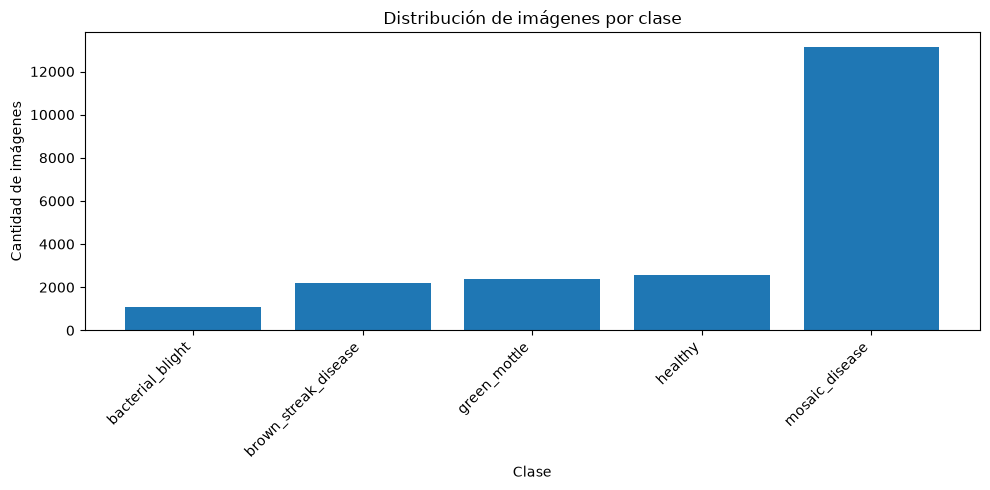

In [21]:
plt.figure(figsize=(10, 5))

plt.bar(
    distribution["class"],
    distribution["image_count"]
)

plt.title("Distribución de imágenes por clase")
plt.xlabel("Clase")
plt.ylabel("Cantidad de imágenes")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    REPORTS_DIR / "class_distribution.png",
    dpi=150
)

plt.show()

In [22]:
distribution.to_csv(
    REPORTS_DIR / "dataset_distribution.csv",
    index=False,
    encoding="utf-8-sig"
)

In [23]:
df_valid["is_duplicate"] = (
    df_valid["sha256"].duplicated(keep=False)
)

duplicados = df_valid[
    df_valid["is_duplicate"]
].sort_values("sha256")

duplicados[
    ["filename", "filepath", "class", "sha256"]
]

,filename,filepath,class,sha256


In [24]:
duplicados.to_csv(
    REPORTS_DIR / "duplicate_images.csv",
    index=False,
    encoding="utf-8-sig"
)

In [25]:
print("Total de archivos de imagen:", len(df))

print(
    "Imágenes válidas:",
    len(df[df["status"] == "valid"])
)

print(
    "Imágenes inválidas:",
    len(df[df["status"] == "invalid"])
)

print(
    "Dimensiones más frecuentes:"
)

print(
    df_valid.groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
    .head(10)
)

Total de archivos de imagen: 21397
Imágenes válidas: 21397
Imágenes inválidas: 0
Dimensiones más frecuentes:
width  height
800    600       21397
dtype: int64


In [26]:
df[df["status"] == "invalid"][
    ["filepath", "status", "error"]
]

,filepath,status,error


In [27]:
classes = sorted(df_valid["class"].unique())

class_mapping = {
    clase: indice
    for indice, clase in enumerate(classes)
}

print(class_mapping)

{'bacterial_blight': 0, 'brown_streak_disease': 1, 'green_mottle': 2, 'healthy': 3, 'mosaic_disease': 4}


In [28]:
mapping_path = REPORTS_DIR / "class_mapping.json"

with open(mapping_path, "w", encoding="utf-8") as f:

    json.dump(
        class_mapping,
        f,
        indent=4,
        ensure_ascii=False
    )